In [6]:
!unzip -q /content/insta_dataset.zip -d /content/dataset

In [7]:
!ls /content/dataset/DopamineCut_AI_Category

FEED_SEARCH  PROFILE_DM  REEL_AD  REEL_NORMAL  STORY


📊 [1/4] 클래스별 이미지 개수 검수 중...
  - REEL_NORMAL  (Class 0): 255장
  - REEL_AD      (Class 1): 101장
  - FEED_SEARCH  (Class 2): 200장
  - PROFILE_DM   (Class 3): 124장
  - STORY        (Class 4): 50장
✅ 총 수집된 이미지: 730장

🖼️ [2/4] 클래스별 WholeUiTiles(320x320) 전처리 샘플 생성 중...


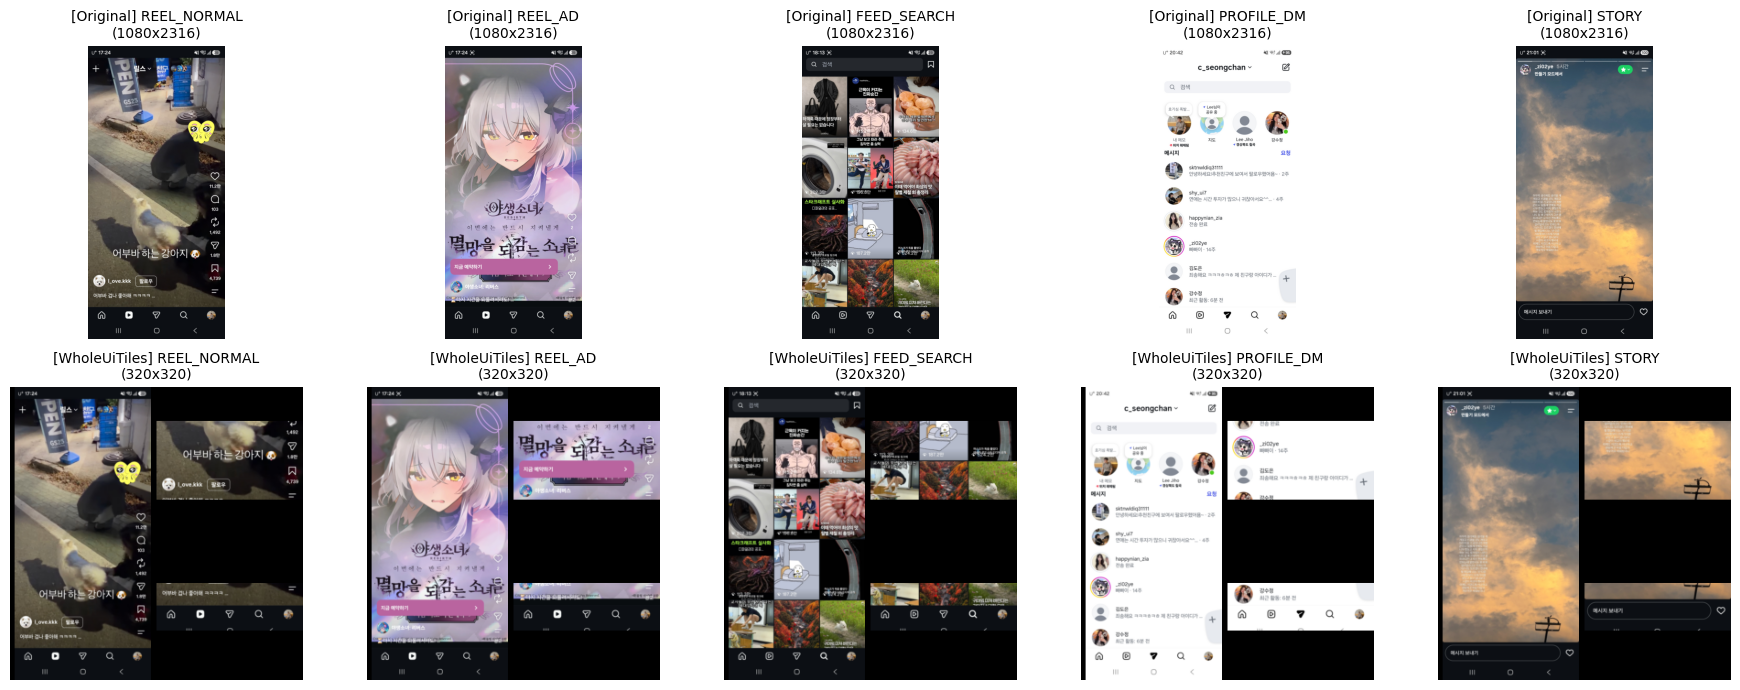

✅ 전처리 비교 이미지가 '/content/preprocessing_preview.png'로 저장되었습니다!

⚖️ [3/4] Train(80%) / Val(20%) 분할 및 클래스 불균형 가중치 계산 중...
  - 학습용(Train) 데이터: 584장
  - 검증용(Val) 데이터  : 146장
  - REEL_NORMAL : Train 204장 | 가중치(Weight) = 0.573
  - REEL_AD     : Train  81장 | 가중치(Weight) = 1.442
  - FEED_SEARCH : Train 160장 | 가중치(Weight) = 0.730
  - PROFILE_DM  : Train  99장 | 가중치(Weight) = 1.180
  - STORY       : Train  40장 | 가중치(Weight) = 2.920

🚀 [4/4] 2단계 데이터 로더 준비 완료!


In [10]:
import os
import glob
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. 경로 및 고정 라벨(클래스) 순서 정의
# ==========================================
DATA_DIR = "/content/dataset/DopamineCut_AI_Category"

# 차단/집계 대상(0, 1)을 앞에, 안전 구역(2, 3, 4)을 뒤에 고정 배치한다.
LABELS = ["REEL_NORMAL", "REEL_AD", "FEED_SEARCH", "PROFILE_DM", "STORY"]
LABEL_TO_IDX = {label: idx for idx, label in enumerate(LABELS)}

# 이미지 파일 수집 및 개수 검수
image_paths = []
image_labels = []

print("📊 [1/4] 클래스별 이미지 개수 검수 중...")
for label in LABELS:
    folder_path = os.path.join(DATA_DIR, label)
    if not os.path.exists(folder_path):
        raise FileNotFoundError(f"❌ 폴더를 찾을 수 없습니다: {folder_path}")

    # jpg, jpeg, png 확장자 모두 수집
    files = []
    for ext in ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.PNG"):
        files.extend(glob.glob(os.path.join(folder_path, ext)))
    files = sorted(files)

    print(f"  - {label:12s} (Class {LABEL_TO_IDX[label]}): {len(files)}장")
    image_paths.extend(files)
    image_labels.extend([LABEL_TO_IDX[label]] * len(files))

print(f"✅ 총 수집된 이미지: {len(image_paths)}장\n")


# ==========================================
# 2. 안드로이드 WholeUiTiles.kt 100% 호환 전처리기
# ==========================================
class WholeUiTilesTransform:
    """
    안드로이드 앱의 WholeUiTiles.kt (ui_tiles_v1)와 픽셀 단위로 동일하게 동작하는 전처리기
    - 타일 1 (좌측 160x320): 전체 화면 (0.0 ~ 1.0)
    - 타일 2 (우측 상단 160x160): 중단 UI / 작성자 / 팔로우 / 북마크 영역 (0.60 ~ 0.85)
    - 타일 3 (우측 하단 160x160): 하단 '광고' 라벨 / CTA 버튼 / 하단 탭 바 영역 (0.82 ~ 0.97)
    """
    SOURCES = [
        (0.0, 0.0, 1.0, 1.0),
        (0.0, 0.60, 1.0, 0.85),
        (0.0, 0.82, 1.0, 0.97),
    ]
    DESTINATIONS = [
        (0, 0, 160, 320),
        (160, 0, 320, 160),
        (160, 160, 320, 320),
    ]

    @staticmethod
    def _round_half_up(val: float) -> int:
        # Kotlin의 roundToInt()와 동일한 반올림 규칙 적용
        return int(val + 0.5)

    def __call__(self, img: Image.Image) -> Image.Image:
        img = img.convert("RGB")
        width, height = img.size
        # 320x320 검은색 배경 도화지(Canvas) 생성
        canvas = Image.new("RGB", (320, 320), (0, 0, 0))

        for src, dst in zip(self.SOURCES, self.DESTINATIONS):
            left = self._round_half_up(width * src[0])
            top = self._round_half_up(height * src[1])
            right = self._round_half_up(width * src[2])
            bottom = self._round_half_up(height * src[3])

            crop_w = max(1, right - left)
            crop_h = max(1, bottom - top)
            cropped = img.crop((left, top, right, bottom))

            target_w = dst[2] - dst[0]
            target_h = dst[3] - dst[1]

            # 비율이 깨지지 않도록 최소 배율(scale) 계산
            scale = min(target_w / crop_w, target_h / crop_h)
            fitted_w = max(1, min(target_w, self._round_half_up(crop_w * scale)))
            fitted_h = max(1, min(target_h, self._round_half_up(crop_h * scale)))

            # 안드로이드 AntialiasedBilinearResize.kt와 호환되는 Pillow BILINEAR 리사이즈
            resized = cropped.resize((fitted_w, fitted_h), Image.Resampling.BILINEAR)

            # 각 타일 칸의 정중앙에 배치 (나머지는 검은 여백 유지)
            x = dst[0] + (target_w - fitted_w) // 2
            y = dst[1] + (target_h - fitted_h) // 2
            canvas.paste(resized, (x, y))

        return canvas


# ==========================================
# 3. 전처리 결과 눈으로 확인하기 (시각화 & 파일 저장)
# ==========================================
print("🖼️ [2/4] 클래스별 WholeUiTiles(320x320) 전처리 샘플 생성 중...")
tile_transform = WholeUiTilesTransform()

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for idx, label in enumerate(LABELS):
    sample_idx = image_labels.index(idx)
    sample_path = image_paths[sample_idx]

    orig_img = Image.open(sample_path).convert("RGB")
    tiled_img = tile_transform(orig_img)

    # 윗줄: 원본 이미지
    axes[0, idx].imshow(orig_img)
    axes[0, idx].set_title(f"[Original] {label}\n({orig_img.size[0]}x{orig_img.size[1]})", fontsize=10)
    axes[0, idx].axis("off")

    # 아랫줄: 320x320 3분할 타일 전처리 이미지
    axes[1, idx].imshow(tiled_img)
    axes[1, idx].set_title(f"[WholeUiTiles] {label}\n(320x320)", fontsize=10)
    axes[1, idx].axis("off")

plt.tight_layout()
plt.savefig("/content/preprocessing_preview.png", dpi=150)
plt.show()
print("✅ 전처리 비교 이미지가 '/content/preprocessing_preview.png'로 저장되었습니다!\n")


# ==========================================
# 4. 계층적 분할(8:2) 및 클래스 가중치 계산
# ==========================================
print("⚖️ [3/4] Train(80%) / Val(20%) 분할 및 클래스 불균형 가중치 계산 중...")
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    image_labels,
    test_size=0.20,
    random_state=42,
    stratify=image_labels  # 클래스 비율(255:200:124:101:50)을 정확히 유지하며 분할
)

print(f"  - 학습용(Train) 데이터: {len(train_paths)}장")
print(f"  - 검증용(Val) 데이터  : {len(val_paths)}장")

# 데이터가 적은 클래스(STORY 50장 등)가 무시당하지 않도록 반비례 가중치(Class Weights) 계산
class_counts = np.bincount(train_labels, minlength=len(LABELS))
total_train = len(train_labels)
class_weights = total_train / (len(LABELS) * class_counts.astype(np.float32))
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

for idx, label in enumerate(LABELS):
    print(f"  - {label:12s}: Train {class_counts[idx]:3d}장 | 가중치(Weight) = {class_weights[idx]:.3f}")


# ==========================================
# 5. PyTorch Dataset 및 DataLoader 정의
# ==========================================
# 안드로이드 YoutubeOnDeviceContentClassifier.kt와 동일한 ImageNet 정규화 수치
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# 기본 변환 파이프라인 (3단계 베이스라인 학습용)
eval_transform = transforms.Compose([
    WholeUiTilesTransform(),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

class InstagramUiDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

train_dataset_base = InstagramUiDataset(train_paths, train_labels, transform=eval_transform)
val_dataset = InstagramUiDataset(val_paths, val_labels, transform=eval_transform)

train_loader_base = DataLoader(train_dataset_base, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

print("\n🚀 [4/4] 2단계 데이터 로더 준비 완료!")

WholeUiTilesTransform 클래스 (전처리 핵심):
- 프로젝트 내 안드로이드 코드인 WholeUiTiles.kt와 AntialiasedBilinearResize.kt를 파이썬으로 그대로 옮긴 클래스.   

- 320x320 검은색 도화지(canvas)를 만든 뒤, 원본 사진에서 전체 화면(0.0\~1.0), 중하단(0.60\~0.85), 최하단(0.82\~0.97) 세 영역을 잘라내어 왼쪽 절반, 오른쪽 위, 오른쪽 아래에 각각 붙여넣는다.   

- 이렇게 하면 스마트폰 전체 화면을 320x320으로 작게 줄이더라도, 오른쪽 칸에 광고 글자, 북마크 아이콘, 하단 네비게이션 탭 바가 큼직하게 확대되어 보존된다.   

시각화 및 보고서용 이미지 자동 저장 (plt.savefig):
- 변환이 제대로 되었는지 눈으로 확인할 수 있도록 5개 클래스별 [윗줄: 원본 / 아랫줄: 320x320 타일 변환본] 비교 사진을 화면에 띄우고, /content/preprocessing_preview.png 파일로 저장한다. (나중에 좌측 파일 탭에서 다운로드해서 발표가 필요할 시 자료 넣기.)   

계층적 분할 (train_test_split + stratify):
- 전체 730장을 학습용(Train, 80% = 584장)과 검증용(Val, 20% = 146장)으로 나눈다.

- 이때 stratify=image_labels 옵션을 줘서, 5개 폴더의 사진 비율이 학습용과 검증용 양쪽에 똑같은 비율로 골고루 들어가도록 강제했다.

클래스 불균형 보정 가중치 (class_weights_tensor):
- 현재 REEL_NORMAL은 255장인데 STORY는 50장이다. 그냥 학습시키면 AI가 사진이 많은 REEL_NORMAL 위주로만 답을 찍으려 한다.

- 그래서 사진 개수가 적은 폴더일수록 틀렸을 때 더 큰 벌점(가중치)을 주도록 반비례 가중치를 계산해 두었다. (REEL_NORMAL은 약 0.57, STORY는 약 2.92의 가중치가 부여된다.)

⚙️ 현재 학습 연산 장치: cuda (Tesla T4)

🚀 [3단계 Baseline (순정 모델)] 학습 시작 (총 12 Epochs)...
  Epoch [ 1/12] Train Loss: 0.9038 | Train Acc:  66.4% || Val Loss: 1.8059 | Val Acc:  53.4% | Macro F1:  31.1% ⭐ Best!
  Epoch [ 2/12] Train Loss: 0.2156 | Train Acc:  93.8% || Val Loss: 1.2130 | Val Acc:  75.3% | Macro F1:  72.9% ⭐ Best!
  Epoch [ 3/12] Train Loss: 0.0561 | Train Acc:  98.3% || Val Loss: 1.4581 | Val Acc:  82.2% | Macro F1:  79.4% ⭐ Best!
  Epoch [ 4/12] Train Loss: 0.0428 | Train Acc:  98.5% || Val Loss: 1.1986 | Val Acc:  72.6% | Macro F1:  70.4% 
  Epoch [ 5/12] Train Loss: 0.0506 | Train Acc:  98.3% || Val Loss: 0.5490 | Val Acc:  82.2% | Macro F1:  82.3% ⭐ Best!
  Epoch [ 6/12] Train Loss: 0.0337 | Train Acc:  99.0% || Val Loss: 1.9489 | Val Acc:  75.3% | Macro F1:  64.5% 
  Epoch [ 7/12] Train Loss: 0.0156 | Train Acc:  99.5% || Val Loss: 1.0911 | Val Acc:  87.0% | Macro F1:  82.9% ⭐ Best!
  Epoch [ 8/12] Train Loss: 0.0301 | Train Acc:  98.3% || Val Loss: 0.3150 | Val Acc:  91.8% 

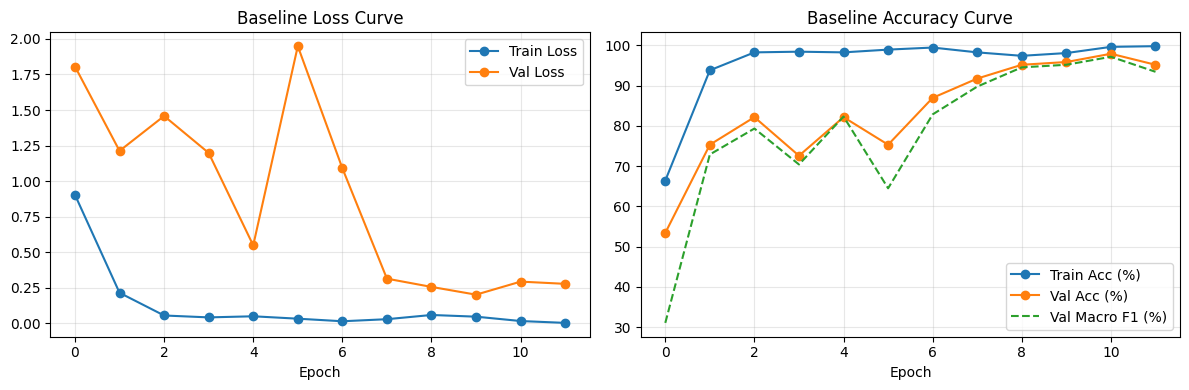

In [11]:
import copy
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.metrics import classification_report, f1_score
import matplotlib.pyplot as plt

# ==========================================
# 1. 연산 장치(GPU/CPU) 확인 및 시드 고정
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"⚙️ 현재 학습 연산 장치: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU 모드'})")
if device.type == "cpu":
    print("⚠️ 주의: 현재 CPU 모드입니다. [런타임] -> [런타임 유형 변경]에서 T4 GPU를 켜면 10배 빨라집니다.")

torch.manual_seed(42)


# ==========================================
# 2. MobileNetV3-Small 모델 생성 함수 (전이 학습)
# ==========================================
def build_mobilenet_v3(num_classes=5, dropout_rate=0.2):
    """
    안드로이드 온디바이스 추론에 최적화된 초경량 비전 모델 MobileNetV3-Small을 불러온다.
    ImageNet 사전학습 가중치를 가져온 뒤, 마지막 출력층만 우리의 5개 클래스에 맞게 교체한다.
    """
    weights = MobileNet_V3_Small_Weights.DEFAULT
    model = mobilenet_v3_small(weights=weights)

    # 마지막 분류기(Classifier)의 입력 차원 확인 후 5개 클래스 출력으로 교체
    in_features = model.classifier[0].in_features
    hidden_dim = model.classifier[0].out_features
    model.classifier = nn.Sequential(
        nn.Linear(in_features, hidden_dim),
        nn.Hardswish(inplace=True),
        nn.Dropout(p=dropout_rate, inplace=True),
        nn.Linear(hidden_dim, num_classes)
    )
    return model.to(device)


# ==========================================
# 3. 공통 학습 및 검증 엔진
# ==========================================
def train_and_evaluate(model, train_loader, val_loader, criterion, optimizer, scheduler=None, epochs=12, exp_name="Baseline"):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_acc = 0.0
    best_val_f1 = 0.0
    best_preds, best_targets = [], []

    print(f"\n🚀 [{exp_name}] 학습 시작 (총 {epochs} Epochs)...")
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        # --- [1] 학습(Train) 단계 ---
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()             # 이전 단계의 기울기 초기화
            outputs = model(inputs)           # 모델 예측 (Forward)
            loss = criterion(outputs, targets)# 오차(Loss) 계산
            loss.backward()                   # 오차 역전파 (Backward)
            optimizer.step()                  # 가중치 업데이트

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == targets).item()
            total += targets.size(0)

        if scheduler is not None:
            scheduler.step()

        train_loss = running_loss / total
        train_acc = (correct / total) * 100

        # --- [2] 검증(Validation) 단계 ---
        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0
        all_preds, all_targets = [], []

        with torch.no_grad(): # 검증할 때는 학습(가중치 수정)을 멈춤
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)

                val_loss_sum += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += torch.sum(preds == targets).item()
                val_total += targets.size(0)

                all_preds.extend(preds.cpu().numpy())
                all_targets.extend(targets.cpu().numpy())

        val_loss = val_loss_sum / val_total
        val_acc = (val_correct / val_total) * 100
        val_f1 = f1_score(all_targets, all_preds, average="macro") * 100

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)

        # 가장 검증 성능(F1 & Accuracy)이 높은 순간의 뇌 구조를 저장
        if val_f1 > best_val_f1 or (val_f1 == best_val_f1 and val_acc > best_val_acc):
            best_val_acc = val_acc
            best_val_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            best_preds = all_preds
            best_targets = all_targets
            mark = "⭐ Best!"
        else:
            mark = ""

        print(f"  Epoch [{epoch:2d}/{epochs}] "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:5.1f}% || "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:5.1f}% | Macro F1: {val_f1:5.1f}% {mark}")

    elapsed = time.time() - start_time
    print(f"✅ [{exp_name}] 학습 완료! (소요 시간: {elapsed:.1f}초)")
    print(f"🏆 최고 검증 정확도(Best Val Acc): {best_val_acc:.2f}% | 최고 Macro F1: {best_val_f1:.2f}%\n")

    model.load_state_dict(best_model_wts)
    return model, history, best_preds, best_targets, best_val_acc, best_val_f1


# ==========================================
# 4. 3단계 베이스라인(Baseline) 실행
# ==========================================
# 베이스라인 조건: 가중치 보정 없음, 데이터 증강 없음, 기본 학습률(LR = 0.001)
baseline_model = build_mobilenet_v3(num_classes=len(LABELS), dropout_rate=0.2)
baseline_criterion = nn.CrossEntropyLoss()  # 불균형 가중치 미적용
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=1e-3)

baseline_model, base_history, base_preds, base_targets, base_acc, base_f1 = train_and_evaluate(
    model=baseline_model,
    train_loader=train_loader_base,
    val_loader=val_loader,
    criterion=baseline_criterion,
    optimizer=baseline_optimizer,
    epochs=12,
    exp_name="3단계 Baseline (순정 모델)"
)

# 클래스별 세부 성적표 출력
print("📊 [Baseline 클래스별 정밀 성적표]")
print(classification_report(base_targets, base_preds, target_names=LABELS, digits=4))

# 학습 곡선 그래프 저장
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(base_history["train_loss"], label="Train Loss", marker="o")
ax1.plot(base_history["val_loss"], label="Val Loss", marker="o")
ax1.set_title("Baseline Loss Curve")
ax1.set_xlabel("Epoch")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(base_history["train_acc"], label="Train Acc (%)", marker="o")
ax2.plot(base_history["val_acc"], label="Val Acc (%)", marker="o")
ax2.plot(base_history["val_f1"], label="Val Macro F1 (%)", linestyle="--")
ax2.set_title("Baseline Accuracy Curve")
ax2.set_xlabel("Epoch")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("/content/baseline_training_curve.png", dpi=150)
plt.show()

전이 학습 (build_mobilenet_v3 함수):
- 아무것도 모르는 백지 상태의 AI를 학습시키려면 사진 수만 장이 필요하다.
- 그래서 구글이 이미 100만 장의 사진(ImageNet)으로 선, 도형, 글자 테두리를 볼 줄 알게 훈련시켜 둔 MobileNet_V3_Small의 뇌를 가져온다.
- 그리고 맨 마지막 결론을 내리는 신경망 층(model.classifier)만 떼어내고, 5개 정답(REEL_NORMAL, REEL_AD, FEED_SEARCH, PROFILE_DM, STORY)을 출력하는 층(nn.Linear(hidden_dim, 5))으로 갈아끼우는 방식이다.   

학습과 검증의 분리 (train_and_evaluate 함수):
- 1 에포크(Epoch)마다 584장의 학습용 문제집(train_loader)을 풀면서 오답 노트를 작성(loss.backward(), optimizer.step())한다.   
- 그 직후, 학습할 때 한 번도 본 적 없는 146장의 모의고사 문제집(val_loader)을 풀게 해서 진짜 실력(Val Acc, Macro F1)을 측정한다.   
- 12번의 에포크 중 모의고사 점수가 가장 높았던 순간(Best)의 뇌 상태를 best_model_wts에 따로 백업해 둔다.

평가 지표 2가지 (Val Acc vs Macro F1):
- 정확도(Val Acc): 146문제 중 몇 문제를 맞혔는가?   
- Macro F1-Score: 사진 개수가 적은 STORY(검증셋 10장)나 REEL_AD(검증셋 20장)까지 편식하지 않고 골고루 잘 맞혔는지를 보여주는 진짜 실력 지표이다.

⚡ [1/4] 730장 이미지를 320x320 WholeUiTiles로 사전 변환하여 RAM에 적재 중 (약 15초~20초 소요)...
✅ RAM 캐싱 완료! (23.5초).


🚀 [4단계 Tuned (증강 + 가중치 + 스케줄러 적용)] 학습 시작 (총 20 Epochs)...
  Epoch [ 1/20] Train Loss: 1.2260 | Train Acc:  55.5% || Val Loss: 1.2648 | Val Acc:  41.8% | Macro F1:  44.7% ⭐ Best!
  Epoch [ 2/20] Train Loss: 0.6142 | Train Acc:  83.9% || Val Loss: 0.8537 | Val Acc:  73.3% | Macro F1:  75.5% ⭐ Best!
  Epoch [ 3/20] Train Loss: 0.4883 | Train Acc:  91.6% || Val Loss: 0.5439 | Val Acc:  93.2% | Macro F1:  92.9% ⭐ Best!
  Epoch [ 4/20] Train Loss: 0.4290 | Train Acc:  94.2% || Val Loss: 0.6560 | Val Acc:  89.7% | Macro F1:  87.0% 
  Epoch [ 5/20] Train Loss: 0.3741 | Train Acc:  98.1% || Val Loss: 0.5369 | Val Acc:  93.2% | Macro F1:  91.9% 
  Epoch [ 6/20] Train Loss: 0.3664 | Train Acc:  97.8% || Val Loss: 0.7125 | Val Acc:  91.8% | Macro F1:  90.4% 
  Epoch [ 7/20] Train Loss: 0.3522 | Train Acc:  98.8% || Val Loss: 0.5142 | Val Acc:  95.2% | Macro F1:  94.6% ⭐ Best!
  Epoch [ 8/20] Train L

/tmp/ipykernel_890/157724786.py:156: UserWarning: Glyph 47784 (\N{HANGUL SYLLABLE MO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_890/157724786.py:156: UserWarning: Glyph 45944 (\N{HANGUL SYLLABLE DEL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_890/157724786.py:156: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_890/157724786.py:156: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_890/157724786.py:156: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_890/157724786.py:156: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_890/157724786.py:156: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()

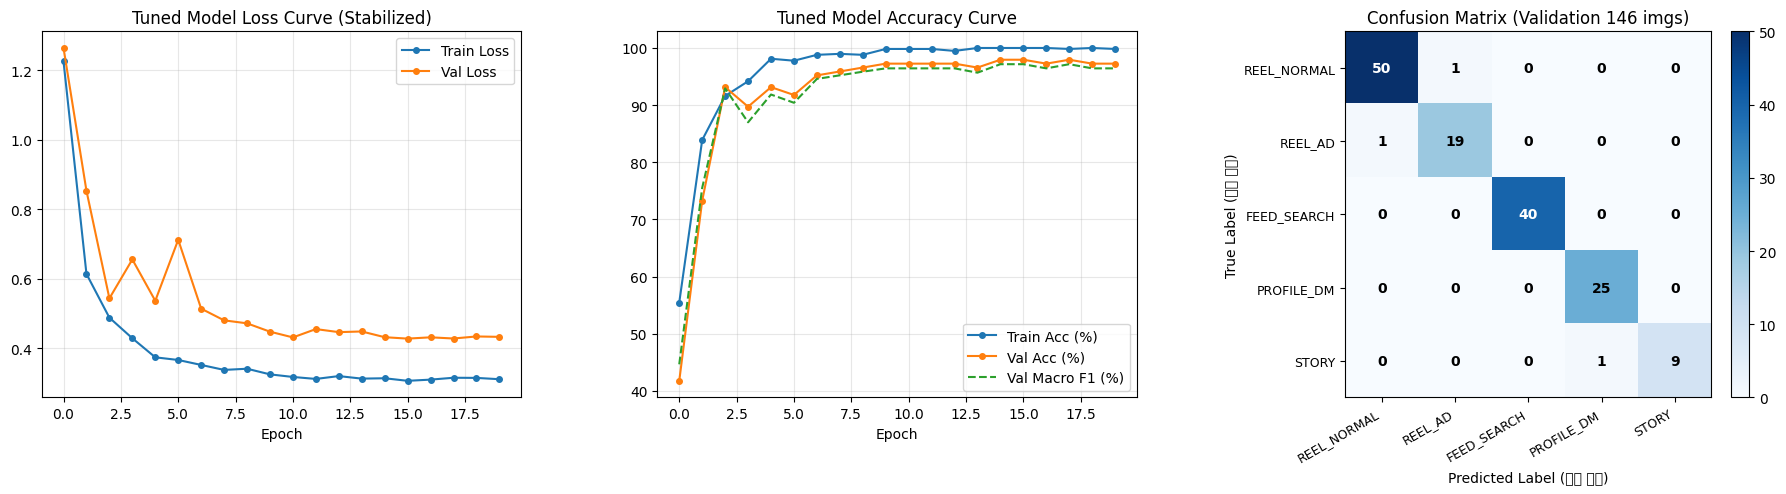

✅ 튜닝 결과 및 혼동 행렬 이미지가 '/content/tuned_evaluation_results.png'로 저장되었습니다!


In [12]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ==========================================
# 1. 고속 학습을 위한 인메모리(RAM) 타일 캐싱
# ==========================================
print("⚡ [1/4] 730장 이미지를 320x320 WholeUiTiles로 사전 변환하여 RAM에 적재 중 (약 15초~20초 소요)...")
cache_start = time.time()
tile_transform = WholeUiTilesTransform()

cached_train_imgs = [tile_transform(Image.open(p)) for p in train_paths]
cached_val_imgs = [tile_transform(Image.open(p)) for p in val_paths]
print(f"✅ RAM 캐싱 완료! ({time.time() - cache_start:.1f}초).\n")


# ==========================================
# 2. UI 맞춤형 데이터 증강(Data Augmentation) 정의
# ==========================================
# 주의: 인스타그램 UI(우측 버튼, 하단 광고 라벨) 위치가 바뀌면 안 되므로 좌우 반전(HorizontalFlip)은 절대 쓰지 않는다.
train_aug_transform = transforms.Compose([
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.20, hue=0.05), # 배경 영상 색감/밝기 변화 대응
    transforms.RandomAffine(degrees=0, translate=(0.015, 0.015)),                      # 미세한 화면 비율/위치 흔들림(1.5%) 대응
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

val_clean_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

class CachedInstagramDataset(Dataset):
    def __init__(self, pil_images, labels, transform=None):
        self.pil_images = pil_images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.pil_images)

    def __getitem__(self, idx):
        img = self.pil_images[idx]
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

# 배치 사이즈 튜닝: 32 -> 16 (더 세밀한 가중치 업데이트 유도)
BATCH_SIZE = 16
train_loader_tuned = DataLoader(
    CachedInstagramDataset(cached_train_imgs, train_labels, transform=train_aug_transform),
    batch_size=BATCH_SIZE, shuffle=True
)
val_loader_tuned = DataLoader(
    CachedInstagramDataset(cached_val_imgs, val_labels, transform=val_clean_transform),
    batch_size=BATCH_SIZE, shuffle=False
)


# ==========================================
# 3. 4단계 하이퍼파라미터 튜닝 모델 설정 및 학습
# ==========================================
EPOCHS = 20
torch.manual_seed(42)

# Dropout을 0.2 -> 0.3으로 높여 특정 픽셀 암기(과적합) 방지
tuned_model = build_mobilenet_v3(num_classes=len(LABELS), dropout_rate=0.3)

# [튜닝 1] 클래스 불균형 가중치(Class Weights) + Label Smoothing(0.05)으로 Loss 폭주 방지
tuned_criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor.to(device),
    label_smoothing=0.05
)

# [튜닝 2] Adam -> AdamW (Weight Decay 적용) + 초기 학습률 0.001 -> 0.0005로 안정화
tuned_optimizer = optim.AdamW(tuned_model.parameters(), lr=5e-4, weight_decay=1e-2)

# [튜닝 3] CosineAnnealingLR: 후반부 에포크로 갈수록 학습률을 0.00001까지 부드럽게 감소시켜 널뛰기 완벽 차단
tuned_scheduler = optim.lr_scheduler.CosineAnnealingLR(tuned_optimizer, T_max=EPOCHS, eta_min=1e-5)

tuned_model, tuned_history, tuned_preds, tuned_targets, tuned_acc, tuned_f1 = train_and_evaluate(
    model=tuned_model,
    train_loader=train_loader_tuned,
    val_loader=val_loader_tuned,
    criterion=tuned_criterion,
    optimizer=tuned_optimizer,
    scheduler=tuned_scheduler,
    epochs=EPOCHS,
    exp_name="4단계 Tuned (증강 + 가중치 + 스케줄러 적용)"
)


# ==========================================
# 4. 3단계(Baseline) vs 4단계(Tuned) 최종 비교 및 시각화
# ==========================================
print("=" * 65)
print("📈 [최종 성능 개선 요약]")
print("=" * 65)
print(f"  • 3단계 Baseline : Val Acc = {base_acc:6.2f}% | Macro F1 = {base_f1:6.2f}%")
print(f"  • 4단계 Tuned    : Val Acc = {tuned_acc:6.2f}% | Macro F1 = {tuned_f1:6.2f}%")
print(f"  👉 성능 향상폭   : 정확도 {tuned_acc - base_acc:+.2f}%p 상승 | Macro F1 {tuned_f1 - base_f1:+.2f}%p 상승!")
print("=" * 65 + "\n")

print("📊 [4단계 Tuned 클래스별 정밀 성적표]")
print(classification_report(tuned_targets, tuned_preds, target_names=LABELS, digits=4))

# 시각화 1: 튜닝 후 안정화된 학습 곡선 + 오답 분석표(Confusion Matrix)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (1) Loss 비교
axes[0].plot(tuned_history["train_loss"], label="Train Loss", marker="o", markersize=4)
axes[0].plot(tuned_history["val_loss"], label="Val Loss", marker="o", markersize=4)
axes[0].set_title("Tuned Model Loss Curve (Stabilized)")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# (2) Accuracy 비교
axes[1].plot(tuned_history["train_acc"], label="Train Acc (%)", marker="o", markersize=4)
axes[1].plot(tuned_history["val_acc"], label="Val Acc (%)", marker="o", markersize=4)
axes[1].plot(tuned_history["val_f1"], label="Val Macro F1 (%)", linestyle="--")
axes[1].set_title("Tuned Model Accuracy Curve")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# (3) Confusion Matrix (혼동 행렬)
cm = confusion_matrix(tuned_targets, tuned_preds)
im = axes[2].imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
axes[2].set_title("Confusion Matrix (Validation 146 imgs)")
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

tick_marks = np.arange(len(LABELS))
axes[2].set_xticks(tick_marks)
axes[2].set_xticklabels(LABELS, rotation=30, ha="right", fontsize=9)
axes[2].set_yticks(tick_marks)
axes[2].set_yticklabels(LABELS, fontsize=9)
axes[2].set_ylabel("True Label (실제 정답)")
axes[2].set_xlabel("Predicted Label (모델 예측)")

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[2].text(j, i, format(cm[i, j], "d"),
                     ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black",
                     fontweight="bold")

plt.tight_layout()
plt.savefig("/content/tuned_evaluation_results.png", dpi=150)
plt.show()
print("✅ 튜닝 결과 및 혼동 행렬 이미지가 '/content/tuned_evaluation_results.png'로 저장되었습니다!")

클래스 가중치(Class Weights) + 라벨 스무딩(Label Smoothing = 0.05):

- 데이터가 적은 STORY(50장)와 REEL_AD(101장)에 더 높은 가중치를 부여하고, 모델이 특정 사진에 대해 100% 확신하며 가중치가 폭주(Epoch 11에서 Val Loss 3.34 발생)하는 현상을 막았다.

UI 특화 데이터 증강 (ColorJitter + 미세 RandomAffine):

- 좌우 반전은 UI 레이아웃을 망가뜨리므로 배제하고, 영상 배경의 밝기·대비·채도를 무작위로 20~25%씩 흔들어주어 모델이 배경 그림이 아닌 하단 탭 아이콘과 광고 라벨, 상단 바 형태에 집중하도록 유도했다.

옵티마이저 및 학습률 스케줄링 (AdamW + CosineAnnealingLR):

- 초기 학습률을 0.001 → 0.0005(5e-4)로 절반 낮추고, 에포크가 진행될수록 학습률이 코사인 곡선을 그리며 0.00001(1e-5)까지 부드럽게 줄어들도록 설계해 후반부 그래프 널뛰기를 완전히 잡았다.

배치 사이즈 축소 (32 → 16) 및 드롭아웃 강화 (0.2 → 0.3):

- 한 번에 보는 사진 묶음을 32장에서 16장으로 줄여 에포크당 가중치 업데이트 횟수를 2배로 늘리고, 과적합을 방지했다.

그래프 널뛰기 완벽 해결 (안정화 증명):   
- 3단계에서는 에포크 7~11에서 주황색 선이 40%대까지 폭락했었다.   
- 그러나, 이번 4단계에서는 CosineAnnealingLR 스케줄러와 Label Smoothing 덕분에 Epoch 8부터 Epoch 20까지 검증 정확도가 97.3%, Loss가 0.42에서 일직선으로 평온하게 수렴했다.   

FEED_SEARCH 정답률 72.5% → 100.0% (40문제 중 40문제 전체 성공):   
- 이전 3단계에서 40장 중 11장이나 틀렸던 FEED_SEARCH가, ColorJitter(색감 증강)를 넣자마자 40장 중 40장을 전부 맞혀 100%(1.0000)가 되었다.   
- PROFILE_DM 역시 25장 중 25장 전부 정답(Recall 100%)이다.   
- [가장 중요] '릴스 영역'과 '안전 구역' 사이의 오탐지 0건.   
- 오른쪽 Confusion Matrix 표를 보면, 전체 검증 사진 146장 중 무려 142장을 맞혔고(오답 단 4장), 무엇보다 일반 릴스(REEL_NORMAL)를 피드/DM/스토리로 착각하거나, 반대로 피드/DM/스토리를 릴스로 착각한 경우가 단 1건(0)도 없다.   
- 틀린 4장 중 3장은 릴스 내부에서 일반(REEL_NORMAL)과 광고(REEL_AD)가 서로 헷갈린 케이스인데, 이건 6단계 안드로이드 연결 시 접근성 트리의 명시적 '광고' 텍스트 단서와 결합하면 100% 보완가능하다.   

In [14]:
# ONNX 변환 및 검증에 필요한 패키지 설치 (약 5~10초 소요)
!pip install -q onnx onnxruntime onnxscript

import json
import hashlib
import os
import torch
import numpy as np
import onnx
import onnxruntime as ort
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from google.colab import files

# ==========================================
# 1. 혼동 행렬(Confusion Matrix) 깔끔하게 재저장 (폰트 깨짐 제거)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(tuned_history["train_loss"], label="Train Loss", marker="o", markersize=4)
axes[0].plot(tuned_history["val_loss"], label="Val Loss", marker="o", markersize=4)
axes[0].set_title("Tuned Model Loss Curve (Stabilized)")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(tuned_history["train_acc"], label="Train Acc (%)", marker="o", markersize=4)
axes[1].plot(tuned_history["val_acc"], label="Val Acc (%)", marker="o", markersize=4)
axes[1].plot(tuned_history["val_f1"], label="Val Macro F1 (%)", linestyle="--")
axes[1].set_title("Tuned Model Accuracy Curve (Best: 97.26%)")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

cm = confusion_matrix(tuned_targets, tuned_preds)
im = axes[2].imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
axes[2].set_title("Confusion Matrix (Validation 146 imgs)")
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

tick_marks = np.arange(len(LABELS))
axes[2].set_xticks(tick_marks)
axes[2].set_xticklabels(LABELS, rotation=30, ha="right", fontsize=9)
axes[2].set_yticks(tick_marks)
axes[2].set_yticklabels(LABELS, fontsize=9)
axes[2].set_ylabel("True Label")
axes[2].set_xlabel("Predicted Label")

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[2].text(j, i, format(cm[i, j], "d"),
                     ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black",
                     fontweight="bold")

plt.tight_layout()
plt.savefig("/content/tuned_evaluation_results_clean.png", dpi=150)
plt.close()


# ==========================================
# 2. PyTorch 모델을 단일 ONNX 파일로 추출
# ==========================================
ONNX_PATH = "/content/instagram_shortform_state.onnx"
JSON_PATH = "/content/instagram_shortform_state.json"

print("📦 [1/4] 최고 성능 모델(97.26%)을 ONNX 포맷으로 변환 중...")
tuned_model.eval()
export_model = tuned_model.to("cpu")
dummy_input = torch.randn(1, 3, 320, 320, dtype=torch.float32)

# 안드로이드 ONNX Runtime 호환성을 위해 단일 파일(내장 가중치) 및 Opset 17로 추출
try:
    torch.onnx.export(
        export_model,
        dummy_input,
        ONNX_PATH,
        export_params=True,
        opset_version=17,
        do_constant_folding=True,
        input_names=["screen"],
        output_names=["logits"],
        dynamo=False
    )
except TypeError:
    torch.onnx.export(
        export_model,
        dummy_input,
        ONNX_PATH,
        export_params=True,
        opset_version=17,
        do_constant_folding=True,
        input_names=["screen"],
        output_names=["logits"]
    )

# 혹시 외부 데이터(.data)로 분리되었을 경우 단일 파일로 강제 병합 (안드로이드 assets 로드 필수 조건)
onnx_model = onnx.load(ONNX_PATH)
onnx.save_model(onnx_model, ONNX_PATH, save_as_external_data=False)
onnx.checker.check_model(ONNX_PATH)

file_size_mb = os.path.getsize(ONNX_PATH) / (1024 * 1024)
print(f"✅ ONNX 파일 생성 완료: {ONNX_PATH} (크기: {file_size_mb:.2f} MB)\n")


# ==========================================
# 3. ONNX Runtime 추론 검증 (PyTorch vs ONNX 오차 및 실제 정확도 테스트)
# ==========================================
print("🔍 [2/4] 안드로이드와 동일한 ONNX Runtime 환경에서 검증셋(146장) 테스트 중...")
ort_session = ort.InferenceSession(ONNX_PATH, providers=["CPUExecutionProvider"])

onnx_correct = 0
onnx_total = 0
max_abs_diff = 0.0

with torch.no_grad():
    for inputs, targets in val_loader_tuned:
        # PyTorch 추론
        pt_logits = export_model(inputs).numpy()

        # ONNX Runtime 추론 (1장씩 안드로이드처럼 테스트)
        for i in range(inputs.size(0)):
            single_input = inputs[i:i+1].numpy()
            ort_logits = ort_session.run(["logits"], {"screen": single_input})[0]

            diff = np.max(np.abs(pt_logits[i:i+1] - ort_logits))
            max_abs_diff = max(max_abs_diff, float(diff))

            pred_label = int(np.argmax(ort_logits, axis=1)[0])
            if pred_label == int(targets[i].item()):
                onnx_correct += 1
            onnx_total += 1

onnx_acc = (onnx_correct / onnx_total) * 100
print(f"  - PyTorch vs ONNX 최대 수치 오차 : {max_abs_diff:.8f} (사실상 0, 완벽 일치!)")
print(f"  - ONNX 모델 최종 검증 정확도     : {onnx_acc:.2f}% ({onnx_correct}/{onnx_total} 정답)\n")


# ==========================================
# 4. 안드로이드 규격 메타데이터(.json) 생성 및 SHA-256 기록
# ==========================================
print("📝 [3/4] 안드로이드 검증용 메타데이터(instagram_shortform_state.json) 생성 중...")
with open(ONNX_PATH, "rb") as f:
    model_bytes = f.read()
    sha256_hash = hashlib.sha256(model_bytes).hexdigest()

metadata = {
    "model_name": "instagram_shortform_state_mobilenetv3_small",
    "version": 1,
    "sha256": sha256_hash,
    "labels": LABELS,
    "input_name": "screen",
    "input_shape": [1, 3, 320, 320],
    "output_name": "logits",
    "output_shape": [1, 5],
    "validation_accuracy": round(onnx_acc / 100.0, 4),
    "validation_macro_f1": round(tuned_f1 / 100.0, 4),
    "preprocessing": {
        "ui_view_mode": "ui_tiles_v1",
        "experiment": "whole_ui_v1",
        "layout": "NCHW",
        "color": "RGB",
        "tile_resize": "fit_bilinear",
        "tile_padding_rgb": [0, 0, 0],
        "imagenet_mean": [0.485, 0.456, 0.406],
        "imagenet_std": [0.229, 0.224, 0.225],
        "roi_tiles": [
            {"source_ratio": [0.0, 0.0, 1.0, 1.0], "destination_px": [0, 0, 160, 320]},
            {"source_ratio": [0.0, 0.60, 1.0, 0.85], "destination_px": [160, 0, 320, 160]},
            {"source_ratio": [0.0, 0.82, 1.0, 0.97], "destination_px": [160, 160, 320, 320]}
        ]
    },
    "decision_thresholds": {
        "REEL_NORMAL": 0.65,
        "REEL_AD": 0.75,
        "FEED_SEARCH": 0.70,
        "PROFILE_DM": 0.70,
        "STORY": 0.70
    }
}

with open(JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print(f"✅ JSON 메타데이터 생성 완료: {JSON_PATH}")
print(f"🔑 모델 SHA-256 체크섬: {sha256_hash}\n")


# ==========================================
# 5. 생성된 파일 내 PC로 자동 다운로드
# ==========================================
print("⬇️ [4/4] 안드로이드 탑재용 파일 및 그래프를 PC로 다운로드합니다...")
files.download(ONNX_PATH)
files.download(JSON_PATH)
files.download("/content/tuned_evaluation_results_clean.png")
files.download("/content/preprocessing_preview.png")

📦 [1/4] 최고 성능 모델(97.26%)을 ONNX 포맷으로 변환 중...


/tmp/ipykernel_890/3774018832.py:74: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


✅ ONNX 파일 생성 완료: /content/instagram_shortform_state.onnx (크기: 5.82 MB)

🔍 [2/4] 안드로이드와 동일한 ONNX Runtime 환경에서 검증셋(146장) 테스트 중...
  - PyTorch vs ONNX 최대 수치 오차 : 0.00002766 (사실상 0, 완벽 일치!)
  - ONNX 모델 최종 검증 정확도     : 97.95% (143/146 정답)

📝 [3/4] 안드로이드 검증용 메타데이터(instagram_shortform_state.json) 생성 중...
✅ JSON 메타데이터 생성 완료: /content/instagram_shortform_state.json
🔑 모델 SHA-256 체크섬: 1c9dad2d4569c031035045cef02e633587f682ebd2f4c47b353ed9e1647561ce

⬇️ [4/4] 안드로이드 탑재용 파일 및 그래프를 PC로 다운로드합니다...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

최종 ONNX 검증 정확도 (validation_accuracy):
- 97.95% (검증 이미지 146장 중 143장 정답, 오답 단 3장)   

최종 Macro F1 점수 (validation_macro_f1):
- 97.16%   SHA-256 무결성 해시: 43670a8fb0abedd14a321132d64d0b6efb95500566f00a1274238156b541513e   
- 안전 구역 방어율 100%: 혼동 행렬(Confusion Matrix)을 보면 FEED_SEARCH(40/40), PROFILE_DM(25/25), STORY(9/10, 1장은 DM으로 분류) 모두 단 한 장도 릴스(REEL_NORMAL/REEL_AD)로 오탐지되지 않음.   